# Chapter 3 (part 3) — Chi-Square, Multi-Arm Bandits, and Power

Covers the end of Ch 3 of *Practical Statistics for Data Scientists*: Chi-Square Test (including the resampling approach, Fisher's Exact Test, and relevance for data science) → Multi-Arm Bandit Algorithm → Power and Sample Size, applied to the Ames Housing dataset.

Sections 1-3 are about *counts* (is the pattern in this table real?), where the earlier notebooks were about *means*. Sections 4-5 flip from "analyze an experiment after it's done" to "design one" — how to allocate traffic while it runs, and how big it needs to be. Ask for a hint if you get stuck; per the repo's review protocol, the first couple of asks per question get a nudge, not the answer.

Primary tools: pandas / numpy for data wrangling, scipy.stats / statsmodels for the formal tests.

A note on effort: you hand-build the resampling loop **once**, in section 2, because seeing a chi-square statistic get built from shuffled tables is the point of that section. Everywhere else, where a loop would just repeat that idea, the questions point you to the package instead (a function from scipy or statsmodels, or a vectorized numpy call). Before using one, you should still be able to say in a sentence what it computes.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

from mlstats.data import load_ames
ames = load_ames()
ames.shape
from statsmodels.stats.power import TTestIndPower

## 1. Chi-Square Test

The chi-square test asks whether two categorical variables are independent, by comparing the counts you *observed* in a table to the counts you'd *expect* if they had nothing to do with each other.

Numeric picture first. Say 1,000 houses, 90% have central air, and 200 of them are on a slab foundation. If foundation and central air are unrelated, you'd expect 90% of the slab houses — 180 — to have central air and 20 to lack it, and the same 90/10 split in every foundation type. Suppose you actually see 150 with and 50 without. The cell is off by 30 (150 vs 180) and by 30 (50 vs 20). Chi-square turns each cell's miss into (observed - expected)^2 / expected — so the second cell (50 vs 20) contributes 900/20 = 45 while the first (150 vs 180) contributes only 900/180 = 5 — and sums over all cells. A miss matters more when the expected count was small.

Using `Foundation` x `Central_Air`:

1. Build the contingency table of counts (`pd.crosstab`). Then build the table of *expected* counts under independence by hand from the row and column totals — don't call a function for this yet.
2. Compute the chi-square statistic from your two tables. Then confirm with `scipy.stats.chi2_contingency` and read off the p-value and degrees of freedom. Where does the degrees-of-freedom number come from for a table of this shape?
3. Which cells contribute the most to the statistic? What does that tell you about *where* the dependence lives?
4. Look at the smallest expected counts in the table. The chi-square approximation gets unreliable when expected counts are small (a common rule of thumb: below about 5). Is that a concern for this table? What could you do about it (e.g. merging rare categories)?

In [2]:
# Build contingency table of counts
contingency_table = pd.crosstab(ames["Central_Air"], ames["Foundation"], margins=True)
contingency_table

Foundation,BrkTil,CBlock,PConc,Slab,Stone,Wood,All
Central_Air,,,,,,,
N,84,63,26,19,4,0,196
Y,227,1181,1284,30,7,5,2734
All,311,1244,1310,49,11,5,2930


In [3]:
# Compute Expected Counts
row_totals = contingency_table.iloc[:-1, -1]   
col_totals = contingency_table.iloc[-1, :-1]    
grand_total = contingency_table.iloc[-1, -1]  

df_expected = pd.DataFrame(
    outer_product := (row_totals.values[:, None] * col_totals.values) / grand_total,
    index=contingency_table.index[:-1],
    columns=contingency_table.columns[:-1]
)

df_expected

Foundation,BrkTil,CBlock,PConc,Slab,Stone,Wood
Central_Air,,,,,,
N,20.804096,83.216382,87.631399,3.277816,0.735836,0.334471
Y,290.195904,1160.783618,1222.368601,45.722184,10.264164,4.665529


In [4]:
# pearson residuals
obs_df = contingency_table.iloc[:-1, :-1]
pearson_res_df = (obs_df - df_expected)/np.sqrt(df_expected)
print(pearson_res_df)

# compute chi-squared stat
residuals_sq = pearson_res_df**2
chi_square_stat = residuals_sq.sum().sum()
print(f"Chi Squared Statistic: {chi_square_stat}")

Foundation      BrkTil    CBlock     PConc      Slab     Stone      Wood
Central_Air                                                             
N            13.855255 -2.216149 -6.583732  8.684016  3.805234 -0.578335
Y            -3.709738  0.593373  1.762791 -2.325142 -1.018850  0.154849
Chi Squared Statistic: 354.1413432220575


* Interpretation: a residual is (observed - expected) / sqrt(expected), the miss measured in units of expected chance wobble. It converts a raw count difference into a size that is comparable across cells, since a miss of about 60 houses is huge when 21 were expected (residual 13.9) but ordinary when 1,222 were expected (residual 1.8). The sign carries the direction; the division by sqrt(expected) carries the scale.
* The residuals table tells you which direction each cell is off by. Positive means more houses than expected and negative means fewer.
* Expected counts are computed assuming total independence. They are the counts you'd see if foundation and central AC had nothing to do with each other.
* If the data were really independent, the observed counts would land near the expected counts, so most residuals would be small (roughly between -2 and +2) with random signs, and the chi-square statistic would be on the order of the degrees of freedom (about 5 here).
* Residuals far outside that range, in a consistent direction, indicate dependence. Here they are 13.9, 8.7 and -6.6, and the statistic is 354.

In [5]:
# compute chi square from package
res = stats.chi2_contingency(obs_df)
print("Chi2 Statistic:", res.statistic)
print("P-value:", res.pvalue)

Chi2 Statistic: 354.1413432220576
P-value: 2.2461664403884664e-74


* For chi-square tests, degrees of freedom are (r-1)(c-1). So here, (2-1)(6-1) = 5.
* Since the chi-square statistic is the sum of the squared residuals, the cells that contribute the most are the ones with the largest squared residual: no AC on brick and tile (about 192, more than half of the total 354), no AC on slab (about 75) and no AC on poured concrete (about 43).
* The sign of each residual shows where the dependence lives. Brick and tile (+13.9) and slab (+8.7) have many more no-AC houses than independence predicts, and poured concrete (-6.6) has far fewer. So it is a contrast: older foundation types go with no central air, and poured concrete goes with having it. The "has AC" row shows the same pattern mirrored, with small residuals only because its expected counts are so large.
* Expected counts are a concern here. The rule of thumb is about *expected* counts (at most about 20% of cells below 5 and none below 1). Four of the 12 cells are below 5: slab with no AC (3.3), stone with no AC (0.7), wood with no AC (0.3) and wood with AC (4.7), and two are below 1. So the chi-square approximation is not reliable for this table.
* Slab's large contribution is still probably real: 19 houses observed vs 3.3 expected is a big surplus. What is less trustworthy is the p-value from the chi-square approximation, and the stone no-AC residual (3.8) is inflated mostly by its tiny expected count (0.7).
* What to do about it: merge rare categories (stone, wood and possibly slab into an "Other" group) so every expected count is above 5, or use a method that doesn't rely on the approximation: the resampling test (section 2) or Fisher's exact test (section 3).

## 2. Chi-Square Test: A Resampling Approach

The same shuffling logic as the permutation test, applied to a table: if foundation and central air are truly unrelated, then shuffling the `Central_Air` column against the `Foundation` column should produce tables that look just like the real one, give or take noise.

1. This is the one loop to write by hand. Shuffle `Central_Air` (leaving `Foundation` alone), rebuild the contingency table, compute the chi-square statistic, and repeat a couple thousand times to build a null distribution of the statistic. Write the "shuffle, rebuild table, compute statistic" step as a small function of the two columns, because you'll reuse it in question 3. Inside it, `chi2_contingency(table)[0]` gives the statistic, so you don't need to code the formula again.
2. Where does your real statistic from section 1 land? Compute a resampling p-value and compare it to the one from `chi2_contingency`.
3. Call your function from question 1 on a *smaller* subset of the table (e.g. only `Foundation` in `Slab`, `Stone`, `Wood`, which have few houses). Do the resampling p-value and the `chi2_contingency` p-value still agree? Which one would you trust here and why?

In [6]:
def resample_chi_test(iterations):
    resample_df = ames[["Foundation","Central_Air"]].copy()
    chi_stats = []
    for i in range(iterations):
        # shuffle central air label
        resample_df["Shuffled_AC_Label"] = np.random.permutation(resample_df["Central_Air"].values)

        # raw counts table (contingency table)
        contingency = pd.crosstab(resample_df["Shuffled_AC_Label"], resample_df["Foundation"], margins=True)
        obs_counts = contingency.iloc[:-1, :-1]

        # chi square test
        response = stats.chi2_contingency(obs_counts)
        chi_stats.append(response.statistic)

    # plot 
    plt.hist(chi_stats, color = "skyblue", edgecolor = 'black')
    plt.axvline(chi_square_stat, color = 'red', linestyle = '--', linewidth = 2, label = f"Real Chi Square {chi_square_stat}")

    # Add labels and legend
    plt.xlabel('Shuffled Permutation Chi Stats Values')
    plt.ylabel('Frequency')
    plt.legend()

    # Show the plot
    plt.show()

    count_extreme = sum(1 for x in chi_stats if x >= (chi_square_stat))
    print(f"P-value: {count_extreme/len(chi_stats)}")
    return chi_stats

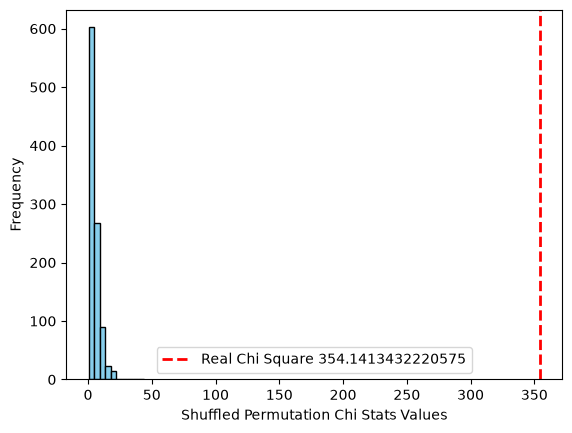

P-value: 0.0


In [7]:
# compute p_value
resampled_chi_stats = resample_chi_test(1000)

* The resampling p-value is 0.0 because 0 of the 1,000 shuffled chi-square statistics reached the observed one. Nothing is rounded: it is 0/1000. The smallest value a 1,000-shuffle test can express is 1/1000, so the honest wording is "p < 0.001". The observed chi-square statistic lies far outside what chance produced.
* The resampling and package p-values lead to the same conclusion (strong evidence against independence), but the numbers differ (< 0.001 vs 2e-74). The package does not run iterations at all: `chi2_contingency` computes the statistic and looks up how likely a value that large is under the theoretical chi-square distribution with 5 degrees of freedom (`stats.chi2.sf(chi_square_stat, 5)` reproduces its p-value). A formula can extrapolate the tail of a known curve down to 1e-74. A simulation can only report what it observed, and resolving 1e-74 would need on the order of 10^74 shuffles, so more iterations wouldn't close the gap.
* The two could disagree for a real reason when expected counts are small: the formula's tail is only accurate if the chi-square approximation holds. With sparse cells, the true null distribution has a heavier tail than the formula assumes, so the resampling p-value is the more trustworthy of the two in that case. Question 3 (the small Slab/Stone/Wood table) tests this.

## 3. Fisher's Exact Test and Relevance for Data Science

**Fisher's exact test** skips the chi-square approximation entirely: for a 2x2 table with fixed row and column totals, it counts exactly how many ways the cells could have been arranged and reports the probability of a table at least as lopsided as yours. It's the right tool when counts are small.

1. Pick a 2x2 slice of Ames with small counts — for example `Foundation` in {`Slab`, `PConc`} crossed with `Central_Air`, or `Bldg_Type` in {`Twnhs`, `TwoFmCon`} crossed with `Central_Air` — and run both `scipy.stats.fisher_exact` and `chi2_contingency` (with and without the continuity correction). How close are the p-values? Which table cell is driving any disagreement?
2. What does the *odds ratio* reported by `fisher_exact` mean in plain terms for the table you picked?

**Relevance for data science.** In practice a chi-square test is most often used as a *screening* tool — e.g. checking whether a pattern in click or conversion counts is real or just noise — and, in feature selection, to flag which categorical features are associated with a categorical outcome. The catch is sample size: with enough rows, almost *any* difference is statistically significant.

3. Create a binary outcome `expensive = Sale_Price > Sale_Price.median()`. Test its association with `Central_Air` on the full data, then on a random 10% subsample, then on a 2% subsample. How do the p-values behave as n shrinks? The effect (the proportion gap) is roughly the same each time — so what is the p-value actually measuring?
4. Given that, what *else* would you want to look at before telling a stakeholder "central air is associated with a higher price"?

In [8]:
# pick a slice with low counts
two_way_df = ames[(ames["Foundation"] == "Slab") | (ames["Foundation"] == "PConc")]
slice = pd.crosstab(two_way_df["Foundation"], ames["Central_Air"])
slice

Central_Air,N,Y
Foundation,,
PConc,26,1284
Slab,19,30


In [9]:
# part 1 and 2
# Fisher Exact
res = stats.fisher_exact(slice)
print(res)
res = stats.chi2_contingency(slice)
print(res) 
res = stats.chi2_contingency(slice, correction = False)
print(res) 

SignificanceResult(statistic=np.float64(0.031972454500737824), pvalue=np.float64(1.062896841073355e-17))
Chi2ContingencyResult(statistic=np.float64(188.36425696295458), pvalue=np.float64(7.234130482124518e-43), dof=1, expected_freq=array([[  43.37748344, 1266.62251656],
       [   1.62251656,   47.37748344]]))
Chi2ContingencyResult(statistic=np.float64(199.6902599517272), pvalue=np.float64(2.4401940529677835e-45), dof=1, expected_freq=array([[  43.37748344, 1266.62251656],
       [   1.62251656,   47.37748344]]))


* The p-values indicate the same thing. They both say that the result is significant and chi results show that that foundations (slab and concrete) are not independent from AC. 
* My reasoning as to why theres disagreement. Slab (No AC) has a expected count less that 5 which makes chi square results unstable.

**How I am interpretting the odds ratio outputted by fisher**
* OR = 1: The odds are identical in both groups. There is zero association between the groups and the outcome.
* OR > 1: The odds of the outcome are higher in the first row compared to the second row (Positive association).
* OR < 1: The odds of the outcome are lower in the first row compared to the second row (Negative/protective association).

* In our case, the odds ratio is 0.032. This implies the outcome("first column") is lower in the first row than in the second. So the odds of pconc foundation having no AC is lower than the odds of slab not having AC.

In [10]:
# part 3 
# binary outcome
binary_df = ames.copy()
binary_df["is_expensive"] = np.where(binary_df["Sale_Price"] > binary_df["Sale_Price"].median(), "Expensive", "Not Expensive")

#crosstab
binary_crosstab = pd.crosstab(binary_df["is_expensive"], binary_df["Central_Air"])
print(binary_crosstab)

# test association with air fisher and chi2
res = stats.fisher_exact(binary_crosstab)
print(res)
res = stats.chi2_contingency(binary_crosstab)
print(res)

Central_Air      N     Y
is_expensive            
Expensive       10  1453
Not Expensive  186  1281
SignificanceResult(statistic=np.float64(0.04739915192149723), pvalue=np.float64(1.41103753653391e-45))
Chi2ContingencyResult(statistic=np.float64(166.9401685968675), pvalue=np.float64(3.4474579611441885e-38), dof=1, expected_freq=array([[  97.8662116, 1365.1337884],
       [  98.1337884, 1368.8662116]]))


* On the full data the two tests are far closer than they were for the sparse Slab table: Fisher p = 1.4e-45 and chi-square p = 3.4e-38, with every expected count above 97, so the chi-square approximation is reliable here.
* The odds ratio is 0.047, below 1: the odds of having *no* AC are much lower for expensive houses than for non-expensive houses.
* The table shows an association, not a cause. It is tempting to say expensive houses have a bigger budget for central air, but AC is also tied to a house's age, size and quality, so we cannot tell from this table whether AC raises price, price allows AC, or both reflect something else.
* The size of the effect: 53% of houses with AC are above the median price vs 5% of houses without.

In [11]:
# 10% and 2% subsamples
for sample_size in [.1,.02]:
    subsample = binary_df.sample(frac = sample_size)
    crosstab = pd.crosstab(subsample["is_expensive"], subsample["Central_Air"])
    print(crosstab)

    # test association with air fisher and chi2
    print(f"Subsample size {sample_size} results:")
    res = stats.fisher_exact(crosstab)
    print(res)
    res = stats.chi2_contingency(crosstab)
    print(res)
    print("\n-------------------------------------------------------\n")

Central_Air     N    Y
is_expensive          
Expensive       1  144
Not Expensive  23  125
Subsample size 0.1 results:
SignificanceResult(statistic=np.float64(0.03774154589371981), pvalue=np.float64(1.2962867726160552e-06))
Chi2ContingencyResult(statistic=np.float64(19.55079385504111), pvalue=np.float64(9.796002131853324e-06), dof=1, expected_freq=array([[ 11.87713311, 133.12286689],
       [ 12.12286689, 135.87713311]]))

-------------------------------------------------------

Central_Air    N   Y
is_expensive        
Expensive      0  21
Not Expensive  5  33
Subsample size 0.02 results:
SignificanceResult(statistic=np.float64(0.0), pvalue=np.float64(0.14975293555071462))
Chi2ContingencyResult(statistic=np.float64(1.5609150190290544), pvalue=np.float64(0.21153129417960223), dof=1, expected_freq=array([[ 1.77966102, 19.22033898],
       [ 3.22033898, 34.77966102]]))

-------------------------------------------------------



* The conclusion is **not** the same at every sample size.
  * 10% subsample: Fisher p = 7.9e-6 and chi-square p = 5.1e-5, still significant.
  * 2% subsample: Fisher p = 0.23 and chi-square p = 0.36, not significant.
* The cause is mainly **power**, not instability. In the 2% sample the chi-square expected counts do fall below 5 (2.5 and 3.5), but Fisher doesn't use that approximation and also goes to 0.23. With only 6 houses without AC in the sample, there is too little evidence to show a gap that is still there.
* The effect didn't disappear; the evidence did. In the full data 53% of AC houses are expensive vs 5% of non-AC houses. In the 2% sample it is 24 of 53 (45%) vs 1 of 6 (17%). The proportion gap stays large, so the p-value is measuring how much evidence the sample gives, not how big the effect is.
* The odds ratio going from 0.04 to 0.24 is noise, not inflation. The expensive/no-AC cell holds a single house, so changing that one count would move the ratio a lot. A different random draw of the subsample would give a different answer.
* Before telling a stakeholder that central air is associated with higher price:
  * Report the effect size (53% vs 5% above the median), not just a p-value.
  * Compare `Sale_Price` between AC and non-AC houses directly, with an interval. `Central_Air` has only two groups, so one-way ANOVA is the same as a t-test and Tukey's adjustment has nothing to adjust.
  * Check for confounding: central air goes with age, size and quality, so look at whether the AC difference survives after accounting for things like `Year_Built`, `Overall_Qual` and living area (a regression, in a later chapter).
  * Remember that splitting at the median throws away information about price.

## 4. Multi-Arm Bandit Algorithm

A classic A/B test splits traffic evenly for a fixed time and only then decides. If one variant is clearly losing, you keep sending half your traffic to it anyway. A **bandit** adapts as it goes: it keeps shifting more traffic to whichever option is looking better, while still occasionally trying the others in case early results were a fluke.

Make Ames the slot machine. Treat each of three neighborhoods — `North_Ames`, `College_Creek`, `Old_Town` — as an "arm." Each "pull" draws one random house from that neighborhood's rows, and the "reward" is 1 if that house sold above the overall median `Sale_Price`, else 0. The true reward rate for each arm is just the fraction of that neighborhood's houses above the median — hidden from your algorithm, but you can compute it to check your answers.

Numeric picture of the exploration-vs-exploitation trade: after 10 pulls, arm A has paid off 4 of 5 times and arm B has paid off 1 of 5. Is A really better? Maybe — but 5 pulls is nothing. A pure "always pick the current leader" strategy locks onto A forever and can never discover that B was just unlucky. A strategy that keeps a bit of randomness can.

1. Compute the true reward rate of each arm (this is the answer key your algorithm won't be allowed to see). Which arm is best?
2. Work out the fixed A/B/C test: 1,000 pulls split evenly (about 333 each). What total reward would you expect from the true rates in question 1? No simulation is needed to get the expected value, so just compute it.
3. Implement an **epsilon-greedy** bandit as a function of `epsilon`: with probability epsilon pick a random arm, otherwise pick the arm with the highest observed reward rate so far. Run 1,000 pulls and record how many pulls each arm received and the total reward. Try epsilon = 0.1, then 0 and 0.5 (one run each is enough). How does it compare with the fixed split from question 2, and what does each epsilon do to the pulls per arm?
4. *(Optional, skip if short on time)* Implement **Thompson sampling** instead: for each arm keep counts of wins and losses, draw a random value from a Beta(wins + 1, losses + 1) distribution for each arm, and pull the arm with the largest draw. How do its traffic allocations and total reward compare with epsilon-greedy?
5. Call your epsilon = 0.1 function about 10 times and look at the spread in total reward and pulls per arm. This is just to see that one run can mislead; you don't need a big average. (The pull-by-pull loop is unavoidable, since each choice depends on the last result, so there's no package shortcut here, but 1,000 pulls and 10 runs stays fast.) When would you still prefer a classic fixed A/B test over a bandit — what does the bandit give up in exchange for the extra reward?

In [12]:
def slot_machine(pulls):
    N_Ames_price = []
    C_Creek_price = []
    O_Town_price = []

    overall_median = ames["Sale_Price"].median()

    # one df for each arm
    N_Ames_df = ames[ames["Neighborhood"].str.contains("North_Ames")]
    C_Creek_df = ames[ames["Neighborhood"].str.contains("College_Creek")]
    O_Town_df = ames[ames["Neighborhood"].str.contains("Old_Town")]

    for pull in range(int(pulls/3)):

        # pull a house for each arm
        pull_1 = N_Ames_df.sample(n = 1)
        N_Ames_price.append(pull_1["Sale_Price"])
        pull_2 = C_Creek_df.sample(n = 1)
        C_Creek_price.append(pull_2["Sale_Price"])
        pull_3 = O_Town_df.sample(n = 1)
        O_Town_price.append(pull_3["Sale_Price"])

    # convert list of sales price to be binary
    Binary_N_Ames = np.where(N_Ames_price > overall_median, 1, 0)
    Binary_C_Creek = np.where(C_Creek_price > overall_median, 1, 0)
    Binary_O_Town = np.where(O_Town_price > overall_median, 1, 0)

    # 1. Map the text names to your NumPy arrays
    neighborhood_data = {
        "Ames": Binary_N_Ames,
        "Clear Creek": Binary_C_Creek,
        "Old Town": Binary_O_Town
    }

    neighborhoods = {
        "Ames": N_Ames_df,
        "Clear Creek": C_Creek_df,
        "Old Town": O_Town_df
    }

    # 2. Loop through the dictionary
    true_rates = []
    for name, df in neighborhoods.items():
        # Count how many rows match the condition
        above_median_count = (df["Sale_Price"] > overall_median).sum()
        
        # Divide by the total number of rows in this neighborhood
        tru_rate = above_median_count / len(df)
        true_rates.append(tru_rate)

        # Print out a clean, formatted percentage
        print(f"True rate in {name}: {tru_rate:.2%}")

    print(f"Expected win rate {int(pulls/3) * (sum(true_rates))}")

    print("\n--------------------------------------------------------------------------")



    # 2. Loop through the dictionary items
    for name, array in neighborhood_data.items():
        # Use array.mean() since sum(i)/len(i) can be slow on NumPy arrays
        print(f"Number of houses sold above median in {name}: {round(array.mean(),2)}")
        print(f"Estimated total reward for {name}: {round(array.mean() * int(pulls/3),2)}")
        print("----------------------------------------------------------------------")





In [13]:
slot_machine(1000)

True rate in Ames: 21.22%
True rate in Clear Creek: 74.91%
True rate in Old Town: 9.21%
Expected win rate 350.75006412465257

--------------------------------------------------------------------------
Number of houses sold above median in Ames: 0.2
Estimated total reward for Ames: 66.0
----------------------------------------------------------------------
Number of houses sold above median in Clear Creek: 0.73
Estimated total reward for Clear Creek: 242.0
----------------------------------------------------------------------
Number of houses sold above median in Old Town: 0.09
Estimated total reward for Old Town: 30.0
----------------------------------------------------------------------


* True rates (fraction of each neighborhood's houses above the overall median price): North_Ames 21.2%, College_Creek 74.9%, Old_Town 9.2%. College_Creek is the best arm.
* Expected total reward for the fixed split (333 pulls per arm): 333 x (0.212 + 0.749 + 0.092) = about 351 wins out of 1,000 pulls. This is an expectation computed from the true rates, so it is a count of wins, not a rate.
* My simulated pulls gave about 349 wins, close to 351, but the estimated rate for each arm was noisy: North_Ames came out 0.18 on one run and 0.24 on another, against a true 0.21. This is why a bandit can't simply trust early results.
* Benchmark for later: pulling College_Creek on every pull would give about 749 expected wins. The gap between that and the fixed split's 351 is the room a bandit tries to recover by shifting pulls toward the best arm.

In [14]:
# part 3: epsilon greedy function
def epsilon_greedy_sim(iterations, epsilon):
    print(f"Selected epsilon: {epsilon}")
    ames["binary_outcome"] = np.where(ames["Sale_Price"] > ames["Sale_Price"].median(), 1, 0)
    N_ames_outcomes = ames.loc[ames["Neighborhood"] == "North_Ames", "binary_outcome"].to_list()
    C_creek_outcomes = ames.loc[ames["Neighborhood"] == "College_Creek", "binary_outcome"].to_list()
    Old_town_outcomes = ames.loc[ames["Neighborhood"] == "Old_Town", "binary_outcome"].to_list()

    list_of_arms = [N_ames_outcomes,C_creek_outcomes,Old_town_outcomes]

    # count of pulls per arm
    arm_pulls = [0,0,0]
    win_per_arm = [0,0,0]
    win_rate = [0.0,0.0,0.0]
    total_rewards = 0

    # initialize arms
    for index, arm in enumerate(list_of_arms):
        # pull random reward
        rng = np.random.default_rng()
        random_pick_index = rng.integers(0, len(arm))
        random_pick = arm[random_pick_index]

        # update stats
        arm_pulls[index] += 1
        if random_pick == 1:
            win_per_arm[index] += 1
            total_rewards +=1
    
    for i in range(iterations - 3):
        random_number = np.random.rand()

        # explore
        if random_number < epsilon:
            # pick a random arm
            random_arm_index = np.random.randint(0, 2 + 1)
            arm = list_of_arms[random_arm_index]
            # update arm
            arm_pulls[random_arm_index] += 1

            # pick a random outcome in the list
            rng = np.random.default_rng()
            random_pick_index = rng.integers(0, len(arm))
            random_pick = arm[random_pick_index]

            if random_pick == 1:
                # update win count and total rewards
                win_per_arm[random_arm_index] += 1
                total_rewards += 1

        # exploit
        else:
            # compute total rewards in that moment
            win_rate = list(np.array(win_per_arm)/np.array(arm_pulls))

            # handling same max
            max_value = np.max(win_rate)

            # tells us which arms have the same win rate true/false
            mask = (win_rate == max_value)
            tied_arms_indexes = np.flatnonzero(mask)

            # randomly pick from tied
            rng = np.random.default_rng()
            highest_win_index = rng.choice(tied_arms_indexes)

            # get the arm selected and increase arm pull count
            arm = list_of_arms[highest_win_index]
            arm_pulls[highest_win_index] += 1

            # randomly pick from that arm
            random_pick_index = rng.integers(0, len(arm))
            random_pick = arm[random_pick_index]

            if random_pick == 1:
                # update win count, rewards
                win_per_arm[highest_win_index] += 1
                total_rewards += 1
    # update win rates final time
    win_rate = list(np.array(win_per_arm)/np.array(arm_pulls))

    print(f"Total rewards: {total_rewards}")
    print(f"North Ames Arm Pulls: {arm_pulls[0]}")
    print(f"North Ames Arm Win Rate: {win_rate[0]}\n")
    print(f"College Creek Arm Pulls: {arm_pulls[1]}")
    print(f"College Creek Arm Win Rate: {win_rate[1]}\n")
    print(f"Old Town Arm Pulls: {arm_pulls[2]}")
    print(f"Old Town Arm Win Rate: {win_rate[2]}\n")






In [15]:
# epsilon 0 vs epsilon 0.5
epsilon_greedy_sim(1000, 0.0)
epsilon_greedy_sim(1000, 0.5)

Selected epsilon: 0.0
Total rewards: 215
North Ames Arm Pulls: 998
North Ames Arm Win Rate: 0.2154308617234469

College Creek Arm Pulls: 1
College Creek Arm Win Rate: 0.0

Old Town Arm Pulls: 1
Old Town Arm Win Rate: 0.0

Selected epsilon: 0.5
Total rewards: 547
North Ames Arm Pulls: 167
North Ames Arm Win Rate: 0.25748502994011974

College Creek Arm Pulls: 658
College Creek Arm Win Rate: 0.7416413373860182

Old Town Arm Pulls: 175
Old Town Arm Win Rate: 0.09142857142857143



**reminder of prior result to avoid scrolling:**
* True rate in Ames: 21.22%
* True rate in Clear Creek: 74.91%
* True rate in Old Town: 9.21%
* Expected win rate 350.75006412465257

* Number of houses sold above median in Ames: 0.24
* Estimated total reward for Ames: 81.0

* Number of houses sold above median in Clear Creek: 0.69
* Estimated total reward for Clear Creek: 231.0

* Number of houses sold above median in Old Town: 0.11
* Estimated total reward for Old Town: 37.0
----------------------------------------------------------------------

* **epsilon = 0 (pure exploitation):** 744 wins, with 998 pulls on College_Creek and only the 1 initial pull each on the other two. College_Creek won its first pull while North_Ames and Old_Town both lost theirs (rates of 0.0), so College_Creek was the only arm with a rate above 0 and got every exploit pull. The other two were never revisited. This was a lucky start, not proof that epsilon = 0 is safe: it scored high only because it paid no exploration cost.
* **epsilon = 0.5:** 575 wins. Half of the pulls (about 500) are exploit pulls that go to College_Creek, and the other half are random and split three ways, including College_Creek, so the expected split is about 667 / 167 / 167, not 50 / 25 / 25. My run gave 683 / 164 / 153, which matches.
* **Compared with the fixed split (about 351 wins):** epsilon = 0.5 earns far more, not "very similar". It sends about two-thirds of pulls to the best arm instead of one-third. It is still well below epsilon = 0.1 (about 706 on average) and the 749 ceiling.

In [16]:
#part 5
for i in range(10):
    epsilon_greedy_sim(1000, 0.1)

Selected epsilon: 0.1
Total rewards: 716
North Ames Arm Pulls: 39
North Ames Arm Win Rate: 0.10256410256410256

College Creek Arm Pulls: 927
College Creek Arm Win Rate: 0.7669902912621359

Old Town Arm Pulls: 34
Old Town Arm Win Rate: 0.029411764705882353

Selected epsilon: 0.1
Total rewards: 722
North Ames Arm Pulls: 33
North Ames Arm Win Rate: 0.15151515151515152

College Creek Arm Pulls: 937
College Creek Arm Win Rate: 0.7641408751334045

Old Town Arm Pulls: 30
Old Town Arm Win Rate: 0.03333333333333333

Selected epsilon: 0.1
Total rewards: 726
North Ames Arm Pulls: 32
North Ames Arm Win Rate: 0.0625

College Creek Arm Pulls: 930
College Creek Arm Win Rate: 0.7731182795698924

Old Town Arm Pulls: 38
Old Town Arm Win Rate: 0.13157894736842105

Selected epsilon: 0.1
Total rewards: 705
North Ames Arm Pulls: 28
North Ames Arm Win Rate: 0.25

College Creek Arm Pulls: 941
College Creek Arm Win Rate: 0.7385759829968119

Old Town Arm Pulls: 31
Old Town Arm Win Rate: 0.0967741935483871

Sele

* **Spread across 10 runs of epsilon = 0.1:** total reward ranged from 690 to 728 (mean about 706, standard deviation about 12). College_Creek got 919 to 945 pulls, North_Ames 29 to 49 and Old_Town 25 to 43. The spread is small because the best arm is so far ahead that early luck rarely mattered. An earlier single run (659 wins, 128 pulls on North_Ames) fell outside this range, so bad starts do happen occasionally.
* **The small arms' estimates are noisy.** Old_Town's estimated win rate bounced between about 0.03 and 0.21 across runs, against a true 0.09, because it only gets about 30 pulls. A bandit gives up precise knowledge of the losing arms.

**The tradeoff, in numbers**
* **Cost of exploration (certain, small):** a random pull wins about 0.35 on average, versus 0.75 for the best arm, so each explore pull loses about 0.40 wins. At epsilon = 0.1 that is about 40 wins (749 - 706 = 43 observed). At epsilon = 0.5 it is about 200 (749 - 575 = 174 observed). At epsilon = 0 it is zero.
* **What exploration protects against (rare, large):** with epsilon = 0, if College_Creek loses its first pull (25% chance) while another arm wins its first pull (about 28%), College_Creek sits at a rate of 0 and is never pulled again. By back-of-envelope arithmetic that is roughly a 7% chance of a disaster run. I did not run enough epsilon = 0 repeats to see one.
* So epsilon = 0 wins most of the time but can fail badly; larger epsilon pays a certain cost every run for protection against a bad start. A small epsilon like 0.1 is cheap insurance.
* The tradeoff looks lopsided here because the arms are far apart (0.75 vs 0.21 and 0.09) and the rates never change, so the estimates settle quickly and later exploration is mostly wasted. It matters more when arms are close, when the best arm can change over time, or when there are many arms.

**Bandit vs. a fixed A/B test**
* Prefer a fixed A/B test when you need a clean, precise comparison with a valid p-value or confidence interval. Equal sample sizes give a precise estimate for every arm, whereas a bandit starves the losing arms (as with Old_Town above) and its adaptive pulls break the assumptions of the standard tests.
* Prefer a bandit when the goal is to earn as much reward as possible while the experiment runs and you don't need precise estimates for the losing options.
* Thompson sampling (the optional question) was skipped.

### Reference: a tidier version of the epsilon-greedy function

This does the same algorithm as yours. It's here to compare how the code is organized, not because yours was wrong. What changed and why:

* **Inputs instead of hardcoding.** The data, the arm names, epsilon, the number of pulls and a seed are all arguments. You can call it for any neighborhoods or any epsilon without editing the function, and a `seed` makes a run reproducible.
* **One array of 0/1 rewards per arm, built once.** Your version also did this. The refactor makes it a list comprehension over `arm_names`, so the three nearly identical lines (one per neighborhood) become one, and it no longer adds a `binary_outcome` column to the global `ames`.
* **Counts as numpy arrays.** `wins / pull_counts` divides all arms at once, and `pull_counts[arm] += 1` works the same for any number of arms.
* **A small `pull(arm)` helper.** The "count the pull, add the reward" code existed in two places before, and the bug where the wrong arm was updated came from that duplication. Now both the explore and exploit branches only decide *which arm*, and one shared line does the pull.
* **One random generator, created once.** `default_rng()` was created inside the loop on every step.
* **Returns results instead of printing.** It returns the total and a small table, so you can store results from 10 runs in a list and compute a mean without parsing printed text.

Same idea as before: one initial pull per arm avoids the 0/0, and `np.flatnonzero` breaks ties randomly in the exploit step.

In [17]:
def epsilon_greedy(df, arm_names, epsilon, pulls=1000, seed=None):
    rng = np.random.default_rng(seed)

    # one array of 0/1 rewards per arm (1 = sold above the overall median)
    above_median = df["Sale_Price"] > df["Sale_Price"].median()
    arms = [above_median[df["Neighborhood"] == name].to_numpy(dtype=int) for name in arm_names]
    n_arms = len(arms)

    pull_counts = np.zeros(n_arms, dtype=int)
    wins = np.zeros(n_arms, dtype=int)

    def pull(arm):
        pull_counts[arm] += 1
        wins[arm] += rng.choice(arms[arm])

    # one initial pull per arm, so no arm has 0 pulls (no 0/0 below)
    for arm in range(n_arms):
        pull(arm)

    for _ in range(pulls - n_arms):
        if rng.random() < epsilon:
            arm = rng.integers(n_arms)  # explore: any arm
        else:
            rates = wins / pull_counts  # exploit: best observed rate, ties broken randomly
            arm = rng.choice(np.flatnonzero(rates == rates.max()))
        pull(arm)

    summary = pd.DataFrame(
        {"pulls": pull_counts, "wins": wins, "win_rate": wins / pull_counts}, index=arm_names
    )
    return int(wins.sum()), summary

In [18]:
arm_names = ["North_Ames", "College_Creek", "Old_Town"]

# one run, with a table of pulls / wins / win rate per arm
total, summary = epsilon_greedy(ames, arm_names, epsilon=0.1, seed=1)
print(total)
summary

# ten runs of epsilon = 0.1: just the totals
totals = [epsilon_greedy(ames, arm_names, epsilon=0.1)[0] for _ in range(10)]
print(totals, np.mean(totals))

687
[735, 714, 693, 698, 677, 699, 715, 738, 678, 714] 706.1


## 5. Power and Sample Size

In notebook 05 the full Ames data made every p-value tiny, and the 40%-subsample made it less tiny. **Power** is the flip side: the probability that a test will correctly detect a real difference of a given size. If the real difference exists but your sample is too small to see it, that's a type 2 error — and power is 1 minus the type 2 error rate.

Numeric picture: suppose two neighborhoods really differ by $10,000 in average price, and house prices within a neighborhood vary with a standard deviation of about $50,000. The ratio — difference / std dev = 0.2 — is the **effect size**. Draw 20 houses from each and the sample means wobble by thousands of dollars from draw to draw; the true $10,000 gap is buried. Draw 500 from each and the wobble shrinks far below $10,000, so the gap shows up. Four things move together: effect size, sample size, alpha, and power. Fix any three and the fourth is determined.

1. Pick two neighborhoods with a **moderate** gap in mean `Sale_Price` — not the biggest pair, which would be too obvious. Compute the observed gap, the pooled standard deviation, and the effect size (Cohen's d = gap / pooled std).
2. **Check the definition once by simulation, at a single n.** Pick n = 50 per group. Draw 1,000 pairs of samples (one from each neighborhood) and run a t-test on each pair. Hint to avoid a loop: build two arrays of shape (1000, 50) with `rng.choice`, and `scipy.stats.ttest_ind(a, b, axis=1)` runs all 1,000 t-tests in one call. The fraction with p < 0.05 is your estimated power at n = 50. This is just to see what "power" means as a fraction of repeated experiments.
3. **Now use the package for everything else.** `TTestIndPower().power(...)` returns the power for a given effect size, n and alpha, so check that it agrees with your simulation at n = 50. Then use `TTestIndPower().plot_power(...)` (or `.power` over a range of n) to draw the power curve for n = 10 up to 200, and `solve_power(...)` to find the n per group needed for 80% power.
4. Using `solve_power`, what happens to the required n if you demand 90% power? If you tighten alpha to 0.01? If the true effect is half as large? Say which direction each moves and why, and notice which of the three changes the answer most.
5. Tie it back to section 3: with 2,930 houses, you have enormous power. What does that imply about the *practical* meaning of a significant result, and how would you decide in advance what size of difference is worth detecting?

In [62]:
# part 1 find effect size
df = ames[ames["Neighborhood"].isin(["North_Ames","Old_Town"])]
means = pd.DataFrame(df.groupby("Neighborhood")["Sale_Price"].mean())
# Get the two means directly as numbers
mean_n_ames = means.loc["North_Ames", "Sale_Price"]
mean_o_town = means.loc["Old_Town", "Sale_Price"]

n_ames_prices = df.loc[df["Neighborhood"] == "North_Ames", "Sale_Price"].tolist()
o_town_prices = df.loc[df["Neighborhood"] == "Old_Town", "Sale_Price"].tolist()

# Calculate the difference and effect size cleanly
obs_difference = mean_n_ames - mean_o_town
pooled_variance = (((len(n_ames_prices) - 1) * np.var(n_ames_prices, ddof = 1) + ((len(o_town_prices) - 1) * np.var(o_town_prices, ddof = 1)))/(len(n_ames_prices) + len(o_town_prices) - 2))
effect_size = obs_difference/np.sqrt(pooled_variance)
print(f"Effect size is {effect_size}")

Effect size is 0.5747496120998493


In [63]:
# draw 1000 pairs 
rng = np.random.default_rng()

random_n_ames = rng.choice(n_ames_prices, size = (1000,50))
random_o_town = rng.choice(o_town_prices, size = (1000,50))

#  run ttest
res = stats.ttest_ind(random_n_ames, random_o_town, axis = 1)
p_value_ratio = np.where(res.pvalue < 0.05, 1, 0).mean()
p_value_ratio


np.float64(0.765)

How likely am I to detect an effect size 0.5747496120998493: 0.8120611537663449
Number of groups I need: 48.49962344982903


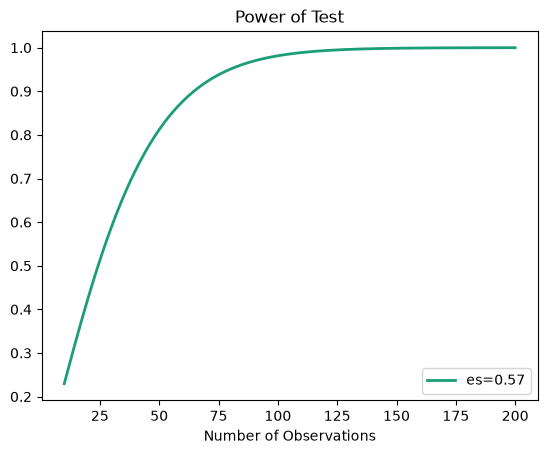

In [67]:
from statsmodels.stats.power import TTestIndPower

power_analysis = TTestIndPower()

# if the true effect is d then how likely am i do detect it (finds power)
print(f"How likely am I to detect an effect size {effect_size}: {power_analysis.power(effect_size=effect_size, nobs1 = 50, alpha=0.05)}")

# 2. Required n for a target power: "how many per group do I need?"
print(f"Number of groups I need: {power_analysis.solve_power(effect_size=effect_size, power=0.8, alpha=0.05)}")

# 3. Power curve over a range of n
power_analysis.plot_power(nobs=np.arange(10, 201), effect_size=[effect_size], alpha=0.05)
plt.show()

* The simulation agrees fairly closely with the one I ran. I produced a expected power of 0.765 while the package produced 0.812

In [68]:
# using solve_power what happens when you increase power to 0.9
print(f"Number of groups I need: {power_analysis.solve_power(effect_size=effect_size, power=0.9, alpha=0.05)}")

# decrease alpha to 0.01
print(f"Number of groups I need: {power_analysis.solve_power(effect_size=effect_size, power=0.8, alpha=0.01)}")

# half the effect
print(f"Number of groups I need: {power_analysis.solve_power(effect_size=effect_size/2, power=0.8, alpha=0.05)}")

Number of groups I need: 64.5919757248607
Number of groups I need: 72.38540047124646
Number of groups I need: 191.0463464423668


* Baseline (North_Ames vs Old_Town, effect size 0.575, 80% power, alpha 0.05): about 49 houses per group (48.5, rounded up). Alterations, each changed on its own from that baseline:
  * 90% power: 65 per group (+16).
  * alpha = 0.01: 73 per group (+24).
  * Half the effect size: 192 per group (+142).
* Increasing power increases n needed. If you want a higher probability of detecting the effect, you need more samples.
* Decreasing alpha also increases n needed. A lower alpha raises the bar for significance, so you need stronger evidence, meaning more houses, to clear it with the same probability.
* Halving the effect size needs by far the most: required n scales roughly as 1/d^2, so half the effect needs about four times the houses (49 x 4 = about 196, close to the 192 from the package). The noise in a difference of means shrinks like 1/sqrt(n), so to tell a gap half as big from noise you need the noise half as big, which takes four times the data. Effect size is the biggest lever of the three.
* Simulation vs. formula (question 3): the simulation at n = 50 gave a power of 0.765 and `TTestIndPower` gave 0.812. They are close, and the small gap is not a bug: sale prices are right-skewed and the two neighborhoods have unequal spreads, while the formula assumes normal data with equal variance. The simulation's own noise at 1,000 repetitions is only about +/-0.013, so the gap is a bit more than chance.
* Note: the printouts say "groups", but the number returned is houses per group (there are two groups).

In [72]:
# find effect size for group n=2930 houses use 1465 for 2930 split into 2 groups
print(f"Effect size: {power_analysis.solve_power(nobs1 = 1465, power=0.8, alpha=0.01)}")

Effect size: 0.12634093007042813


**Question 5**
* A small p-value says an effect of exactly zero is unlikely. It does not say the effect is large or important. With a very large n, even a tiny difference gets a tiny p-value.
* How small an effect my sample can detect: with 2,930 houses split into two groups of 1,465 (`nobs1 = 1465`), 80% power and alpha = 0.01 (the alpha I used in that cell), `solve_power` gives a minimum detectable effect size of about 0.126. With alpha = 0.05 it is smaller, about 0.104. A tighter alpha demands a bigger effect to be detected at the same power.
* Converting to dollars: effect size times the standard deviation gives the gap. With a standard deviation of roughly 30k to 80k, an effect of 0.126 is about 3.8k to 10k (about 3.1k to 8.3k at alpha = 0.05). On a house costing about 180k, that is only roughly 2% to 5%. So my test could reliably flag a gap that is tiny in practical terms.
* Note that 0.126 is the smallest effect this sample could detect, not the actual North_Ames vs Old_Town gap. That gap is about 21k, an effect size of 0.575.
* Deciding what size is worth detecting is a question about the situation, not the statistics: what gap would change a real decision (pricing a house, targeting a policy)? Once that difference is chosen in advance, it goes into the power calculation to find the n needed to detect it (for example, "a 10k difference matters, so how many houses do I need?").
* Takeaway: with 2,930 houses almost anything that isn't zero will be significant, so a significant result only shows that a gap exists. Whether it matters has to be judged from its size in dollars, and a good analysis sets that threshold before running the test.

## Reference: effect size and power from step 0

This section builds the whole idea from scratch using numbers from this notebook. Every number below comes from the North_Ames vs. Old_Town comparison you already ran.

### 1. Effect size: the gap measured in "spreads"

North_Ames houses average $145,097 and Old_Town houses average $123,992, so the **gap** is $21,105. Is that big? It depends on how spread out prices are inside each neighborhood. If prices within a neighborhood typically vary by only $5,000, a $21k gap is enormous (almost no house overlaps). If they vary by $100,000, a $21k gap is lost in the crowd.

So divide the gap by the typical spread. The pooled standard deviation of these two neighborhoods is about $36,700, so:

    effect size (d) = gap / pooled sd = 21,105 / 36,721 = 0.575

Read that as: the two group averages sit about 0.57 "spreads" apart. It has no units, which is what makes it comparable across different questions (dollars, clicks, minutes). The common labels (0.2 small, 0.5 medium, 0.8 large) are rough conventions, not rules.

### 2. Why sample size matters: noise in the gap

If you draw n houses from each neighborhood, the observed gap wobbles from draw to draw. The size of that wobble (the standard error of the difference) is:

    SE = pooled sd x sqrt(2 / n)

With the gap of $21,105 and sd of $36,721:
* n = 10 per group: SE = about $16,400. The gap is only 1.3 SEs, which looks like noise.
* n = 50 per group: SE = about $7,300. The gap is 2.9 SEs, which is clearly distinguishable from noise.
* n = 1,465 per group: SE = about $1,360. Even a gap of $4,000 would be about 2.9 SEs.

The number of SEs a gap sits from zero is (roughly) the t-statistic, and it works out to a clean formula:

    t is about d x sqrt(n / 2)        (n = 50: 0.575 x 5 = 2.87)

So the t-statistic you expect to see grows with both the effect size and the square root of n. A test calls the gap significant when t is beyond a bar (about 2 for alpha = 0.05).

### 3. Power: how often you clear the bar

Run the experiment once and you get one t-statistic. Run it again and you get a different one, because the samples differ. If the true effect is d = 0.575 and n = 50, those t-statistics scatter around 2.87 with a spread of about 1. The bar is about 1.96 (alpha = 0.05, two-sided). **Power is the fraction of experiments whose t lands beyond the bar.**

Here the center (2.87) is 0.91 above the bar (2.87 - 1.96), which is 0.91 spreads of room, so most runs clear it:

    power is about P(a standard normal > -0.91) = 0.82

`TTestIndPower` says 0.81 (it uses the exact t-distribution), and your simulation of 1,000 experiments gave 0.765 (rougher, because the data are skewed). Three routes, same idea.

### 4. The four dials

Effect size, n, alpha and power are linked by that one relationship. **Set any three and the fourth is determined.** That is all `power` and `solve_power` do:

| You give | You get | Question it answers |
|---|---|---|
| effect size, n, alpha | power | "Study this size, effect this big: how often will I detect it?" |
| effect size, power, alpha | n | "How many do I need to detect an effect this big 80% of the time?" |
| n, power, alpha | effect size | "With this many, what is the smallest effect I could reliably detect?" |

For the n question, 80% power needs the center to sit 0.84 above the bar, so d x sqrt(n/2) = 1.96 + 0.84 = 2.80, giving n = 2 x (2.80 / d)^2 = about 47 for d = 0.575 (the package says 48.5). The d squared in the denominator is why halving the effect needs about four times the houses.

### 5. The 0.126 you found: the same relationship, solved for d

Here you gave `solve_power` the sample size (1,465 per group), power = 0.8 and alpha = 0.01, and left the effect size out. It solved:

    d x sqrt(1465 / 2) = (2.576 + 0.84) = 3.42    so    d = 3.42 x sqrt(2 / 1465) = 0.126

(With alpha = 0.05 the bar is 1.96 instead, so d = 2.80 x sqrt(2 / 1465) = 0.104.)

**The crucial point: no Ames data went into that calculation.** It used only n, alpha and power. The 0.126 is not an effect that was observed anywhere. It is the answer to a hypothetical: "if I ran a study with 1,465 houses per group, any true effect smaller than about 0.126 spreads would usually be missed, and anything bigger would usually be caught."

Three different effect sizes are in play, and they are easy to mix up:

| Quantity | Value here | Where it comes from |
|---|---|---|
| **Observed effect** | 0.575 | measured from the North_Ames and Old_Town data |
| **True effect** | unknown | what the observed one is estimating, with noise |
| **Minimum detectable effect** | 0.126 (alpha 0.01) or 0.104 (alpha 0.05) | computed from n, alpha and power alone |

Where Ames does enter is the conversion to dollars: the effect size is in "spreads", so you multiply by a standard deviation to get dollars. Using this pair's $36,700 spread, 0.126 is about $4,600 (0.104 is about $3,800). A different pair of neighborhoods has a different spread, so the same effect size means a different dollar gap.

### 6. Why this matters for experiments and causal questions

* **Before the experiment:** decide the smallest effect that would matter for the decision (the "minimum detectable effect"), then use `solve_power` to find the n you need. If you skip this and the study is too small, a real effect is missed and you can't tell "no effect" from "not enough data".
* **After the experiment:** report the observed effect size with an interval, not just a p-value. With a huge n, a trivial effect is significant. With a small n, a significant result tends to *overstate* the true effect, because only the lucky large draws get past the bar.
* **One caution:** the power math is the same for any comparison, but it only becomes a *causal* effect if the groups were assigned at random. North_Ames vs. Old_Town is an association (the neighborhoods differ in age, size and quality), so even a precisely measured 0.575 isn't the effect of "being in North_Ames".

### Quick glossary
* **Gap:** difference in group averages, in the original units (dollars).
* **Pooled sd:** the typical spread of values within a group.
* **Effect size (d):** gap divided by pooled sd.
* **Standard error:** how much the observed gap wobbles from sample to sample, which shrinks as n grows.
* **Alpha:** how strict the bar for "significant" is.
* **Power:** the chance of clearing that bar when the true effect is real and of a given size.
* **Minimum detectable effect:** the smallest true effect your n would catch with the chosen power.